# 01_Natural regime training: Hydro-stgat

## 1. Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch_geometric.nn import GATConv
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import json
import numpy as np
import pandas as pd
from collections import defaultdict
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline

## 2. Configuration

In [59]:
# =============================================================================
# CONFIGURATION
# =============================================================================
CFG = dict(
    # Input dataset
    npz_path      = 'dataset_PI_STGAT_lagged.npz',
    metadata_path = 'metadata_PI_STGAT_lagged.json',

    # Transit physics
    max_lag       = 30,    # max lags
    v_km_per_day  = 51.84,  # transit velocity: 0.3 m/s ≈ 25.9 km/día

    # Architecture
    window_gru    = 15,    #  GRU window
    hidden_dim    = 64,    # hidden dimension

    # Training
    batch_size    = 32,
    lr            = 1e-3,
    epochs        = 20,
    patience      = 12,    # early stopping

    # Mode: False = train, True = just validation
    eval_only     = False,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")
print(f"Configuración: {CFG}")

Dispositivo: cpu
Configuración: {'npz_path': 'dataset_PI_STGAT_lagged.npz', 'metadata_path': 'metadata_PI_STGAT_lagged.json', 'max_lag': 30, 'v_km_per_day': 51.84, 'window_gru': 15, 'hidden_dim': 64, 'batch_size': 32, 'lr': 0.001, 'epochs': 20, 'patience': 12, 'eval_only': False}


## 3. Hydrological metrics

In [3]:
# =============================================================================
# Hydrological metrics
# =============================================================================
def calculate_nse(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    denom = np.sum((y_true - np.mean(y_true)) ** 2)
    if denom == 0:
        return 0.0
    return float(1.0 - np.sum((y_true - y_pred) ** 2) / denom)

def calculate_kge(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    if len(y_true) < 2 or np.std(y_true) == 0 or np.std(y_pred) == 0:
        return 0.0
    r = np.corrcoef(y_true, y_pred)[0, 1]
    if np.isnan(r):
        r = 0.0
    alpha = np.std(y_pred) / np.std(y_true)
    mean_true = np.mean(y_true)
    beta = np.mean(y_pred) / (mean_true if mean_true != 0 else 1e-5)
    return float(1.0 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2))

print("Metrics defined: NSE, KGE")

Métricas definidas: NSE, KGE


## 4. M_lag constructor

In [60]:
# =============================================================================
# Routing tensor  M_lag [max_lag+1, N, N]
# =============================================================================
def build_lagged_routing_matrix(edge_index, reach_lengths, N,
                                 v_km_per_day=51.84, max_lag=30):
    """
    M_lag[tau, i, j] = 1 
    Reservoirs --> reach_lengths[u] = 0  →  tau = 0.
    """
    # 1. direct lags
    direct_lag = {}
    for k in range(edge_index.shape[1]):
        u = int(edge_index[0, k])
        v = int(edge_index[1, k])
        L = float(reach_lengths[u])
        tau = 0 if L <= 0 else max(1, int(np.ceil(L / v_km_per_day)))
        direct_lag[(u, v)] = tau

    # 2. Accumulation in topological order
    cumulative_lag = defaultdict(dict)
    for (u, v), tau in direct_lag.items():
        cumulative_lag[v][u] = tau

    sorted_nodes = sorted(range(N), key=lambda x: reach_lengths[x])
    for v_idx in sorted_nodes:
        parents = [(u, tau) for (u, v), tau in direct_lag.items() if v == v_idx]
        for u_idx, tau_direct in parents:
            for ancestor, tau_to_u in cumulative_lag[u_idx].items():
                total = tau_to_u + tau_direct
                if ancestor not in cumulative_lag[v_idx] or cumulative_lag[v_idx][ancestor] > total:
                    cumulative_lag[v_idx][ancestor] = total

    # 3. Tensor construction
    M_lag = np.zeros((max_lag + 1, N, N), dtype=np.float32)
    for i in range(N):
        M_lag[0, i, i] = 1.0   # aportación propia
        for j, tau in cumulative_lag[i].items():
            M_lag[min(tau, max_lag), i, j] = 1.0

    truncated = sum(1 for i in cumulative_lag
                    for j, tau in cumulative_lag[i].items() if tau > max_lag)
    print(f"M_lag builded: shape={M_lag.shape}, nnz={int(M_lag.sum())}, "
          f"truncated pairs={truncated}")
    return M_lag

## 5. Dataset

In [61]:
# =============================================================================
# DATASET
# =============================================================================
class RainfallRunoffDatasetLagged(Dataset):
    """
    returns:
        x_history : [N, W_total, C]   W_total = max_lag + window_gru
        y_val     : [N]               stremaflow in t (log1p-scale)
    """
    def __init__(self, dynamic_tensor, climate_indices, target_index,
                 window_gru, max_lag):

        self.dyn     = dynamic_tensor
        self.ci      = climate_indices
        self.ti      = target_index
        self.W       = max_lag + window_gru
        self.n       = len(dynamic_tensor) - self.W

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        t = idx + self.W
        x = self.dyn[t - self.W : t, :, self.ci]   # [W, N, C]
        x = np.transpose(x, (1, 0, 2))             # [N, W, C]
        y = self.dyn[t, :, self.ti]                # [N]
        return (torch.tensor(x, dtype=torch.float32),
                torch.tensor(y, dtype=torch.float32))

print("Dataset defined: RainfallRunoffDatasetLagged")

Dataset definido: RainfallRunoffDatasetLagged


## 6. natural hydrostgat model

In [62]:
# =============================================================================
# MODEL  PI-STGAT with physical routing
# =============================================================================
#
# Architecture:
#   1. GRU  →  h_t [B*N, H]
#   2. GAT  → h_t  →  h_s [B*N, H] 
#   3. Regressor → r_base [B, N] 
#   4. Lag head  → [B, N, L]
#   5. Routing   → einsum with M_lag

class PISTGATLagged(nn.Module):
    def __init__(self, num_climate_features, static_dim, hidden_dim,
                 window_gru, max_lag, num_heads=2):
        super().__init__()
        self.W_gru   = window_gru
        self.max_lag = max_lag
        self.L       = max_lag + 1

        # 1. temporal encoder
        self.gru = nn.GRU(num_climate_features, hidden_dim,
                          num_layers=1, batch_first=True)

        # 2. spatial encoder
        self.gat = GATConv(hidden_dim, hidden_dim // num_heads,
                           heads=num_heads, concat=True)

        # 3. based runoff  [H + S → 1]
        self.regressor = nn.Sequential(
            nn.Linear(hidden_dim + static_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 1),
        )

        # 4. lag weigths [H → L]
        self.lag_weights = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, self.L),
            nn.Softmax(dim=-1) 
        )

        # Buffer for M_lag 
        self.register_buffer('M_lag', torch.zeros(1))

    def set_mlag(self, M_lag_np):
        """After building the model."""
        self.M_lag = torch.tensor(M_lag_np, dtype=torch.float32)

    def forward(self, x_history, edge_index, x_static):
        """
        x_history  : [B, N, W_total, C]   W_total = max_lag + window_gru
        edge_index  : [2, E]
        x_static    : [N, S]
        Returns     : [B, N]  cummulated streamflow in log1p-scale
        """
        B, N, W_total, C = x_history.shape

        # ------------------------------------------------------------------
        # 1. GRU
        # ------------------------------------------------------------------
        x_flat = x_history.view(B * N, W_total, C)
        _, h   = self.gru(x_flat)
        h      = h.squeeze(0)            # [B*N, H]

        # ------------------------------------------------------------------
        # 2. GAT
        # ------------------------------------------------------------------
        offsets  = torch.arange(B, device=h.device) * N
        ei_batch = torch.cat([edge_index + offsets[i] for i in range(B)], dim=1)
        h_s      = F.relu(self.gat(h, ei_batch))   # [B*N, H]
        h_s_2d   = h_s.view(B, N, -1)              # [B, N, H]

        # ------------------------------------------------------------------
        # 3. runoff
        # ------------------------------------------------------------------
        x_static_b = x_static.unsqueeze(0).expand(B, -1, -1)  # [B, N, S]
        h_combined = torch.cat([h_s_2d, x_static_b], dim=-1)  # [B, N, H+S]
        r_base     = F.softplus(
            self.regressor(h_combined)
        ).squeeze(-1)                                           # [B, N]

        # ------------------------------------------------------------------
        # 4. lag weigths
        # ------------------------------------------------------------------
        w = self.lag_weights(h_s_2d)   # [B, N, L]

        #  lag: r_lag[b, n, l] = r_base[b,n] * w[b,n,l]
        r_lag = r_base.unsqueeze(-1) * w   # [B, N, L]  →  [B, N, L]

        # ------------------------------------------------------------------
        # 5. Routing with M_lag via einsum
        #    M_lag[l, i, j] = 1 si j → i in lag l
        #    q[b, i] = sum_l sum_j  r_lag[b, j, l] * M_lag[l, i, j]
        # ------------------------------------------------------------------
        M = self.M_lag   # [L, N, N]
        q_accum = torch.einsum('bnl,lmn->bm', r_lag, M)   # [B, N]

        return torch.log1p(q_accum)

Modelo eficiente definido: PISTGATLagged
  - 1 pasada GRU sobre toda la historia
  - 1 pasada GAT espacial
  - lag_weights aprende la importancia de cada retardo por nodo
  - Routing con einsum sobre M_lag


## 7. Upload data

In [63]:
# =============================================================================
# upload data
# =============================================================================
print("uploading dataset...")
data     = np.load(CFG['npz_path'])
with open(CFG['metadata_path'], 'r') as f:
    metadata = json.load(f)

edge_index_np      = data['edge_index']        # [2, E]
static_features_np = data['static_features']   # [N, S]
dynamic_tensor     = data['dynamic_tensor']    # [T, N, F]
reach_lengths_np   = data['reach_km']          # [N]

mass_list        = metadata['mass_list']
dynamic_features = metadata['dynamic_features']
N                = len(mass_list)
T                = len(dynamic_tensor)

climate_vars    = ['P_mm', 'ETP_mm', 'Tmax', 'Tmin', 'Month_Sin', 'Month_Cos']
climate_indices = [dynamic_features.index(v) for v in climate_vars]
target_index    = dynamic_features.index('Q_nat_hm3')


Cargando dataset...
Nodos: 140 | Pasos temporales: 14702
Features climáticas (6): ['P_mm', 'ETP_mm', 'Tmax', 'Tmin', 'Month_Sin', 'Month_Cos']
Target: Q_nat_hm3  (índice 2)


## 8. Build M_lag

In [64]:
# =============================================================================
# Build M_lag
# =============================================================================
max_lag = CFG['max_lag']

if 'm_lag_tensor' in data and data['m_lag_tensor'].shape[0] - 1 == max_lag:
    M_lag_np = data['m_lag_tensor']
    print(f"M_lag upload from npz: {M_lag_np.shape}")
else:
    print("rebuilding M_lag")
    M_lag_np = build_lagged_routing_matrix(
        edge_index_np, reach_lengths_np, N,
        v_km_per_day=CFG['v_km_per_day'],
        max_lag=max_lag
    )

Reconstruyendo M_lag (puede tardar unos segundos)...
M_lag construida: shape=(31, 140, 140), nnz=521, pares truncados=0


## 9. Splits y DataLoaders

In [65]:
# =============================================================================
# SPLITS Y DATALOADERS
# =============================================================================
W_total   = max_lag + CFG['window_gru']
train_end = int(T * 0.8)
val_end   = int(T * 0.9)

train_dyn = dynamic_tensor[:train_end]
val_dyn   = dynamic_tensor[train_end:val_end]
test_dyn  = dynamic_tensor[val_end:]

kw = dict(climate_indices=climate_indices, target_index=target_index,
          window_gru=CFG['window_gru'], max_lag=max_lag)

train_ds = RainfallRunoffDatasetLagged(train_dyn, **kw)
val_ds   = RainfallRunoffDatasetLagged(val_dyn,   **kw)
test_ds  = RainfallRunoffDatasetLagged(test_dyn,  **kw)

train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=CFG['batch_size'], shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=CFG['batch_size'], shuffle=False)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

edge_index = torch.tensor(edge_index_np, dtype=torch.long).to(device)
x_static   = torch.tensor(static_features_np, dtype=torch.float32).to(device)

Train: 11716 | Val: 1425 | Test: 1426
Ventana total por muestra: 45 días  (max_lag=30 + window_gru=15)


## 10. instantiate the model

In [66]:
# =============================================================================
# instantiate the model and upload M_lag as buffer
# =============================================================================
model = PISTGATLagged(
    num_climate_features = len(climate_indices),
    static_dim           = static_features_np.shape[1],
    hidden_dim           = CFG['hidden_dim'],
    window_gru           = CFG['window_gru'],
    max_lag              = max_lag,
).to(device)

model.set_mlag(M_lag_np)
model.M_lag = model.M_lag.to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {total_params:,}")

Parámetros entrenables: 28,256
M_lag en dispositivo: cpu, shape: torch.Size([31, 140, 140])


## 11. training

Epoch 001/100 | Train: 0.06281 | Val: 0.03281
Epoch 002/100 | Train: 0.02638 | Val: 0.01615
Epoch 003/100 | Train: 0.02245 | Val: 0.01989
Epoch 004/100 | Train: 0.02126 | Val: 0.01519
Epoch 005/100 | Train: 0.02050 | Val: 0.01552
Epoch 006/100 | Train: 0.01965 | Val: 0.01556
Epoch 007/100 | Train: 0.01888 | Val: 0.01676
Epoch 008/100 | Train: 0.01819 | Val: 0.01613
Epoch 009/100 | Train: 0.01799 | Val: 0.01506
Epoch 010/100 | Train: 0.01760 | Val: 0.02161
Epoch 011/100 | Train: 0.01716 | Val: 0.01619
Epoch 012/100 | Train: 0.01667 | Val: 0.01879
Epoch 013/100 | Train: 0.01596 | Val: 0.01730
Epoch 014/100 | Train: 0.01571 | Val: 0.01791
Epoch 015/100 | Train: 0.01494 | Val: 0.01695
Epoch 016/100 | Train: 0.01447 | Val: 0.01818
Epoch 017/100 | Train: 0.01420 | Val: 0.01959
Epoch 018/100 | Train: 0.01356 | Val: 0.01870
Epoch 019/100 | Train: 0.01293 | Val: 0.01723
Epoch 020/100 | Train: 0.01258 | Val: 0.01865
Epoch 021/100 | Train: 0.01206 | Val: 0.01844
Early stopping en época 21.


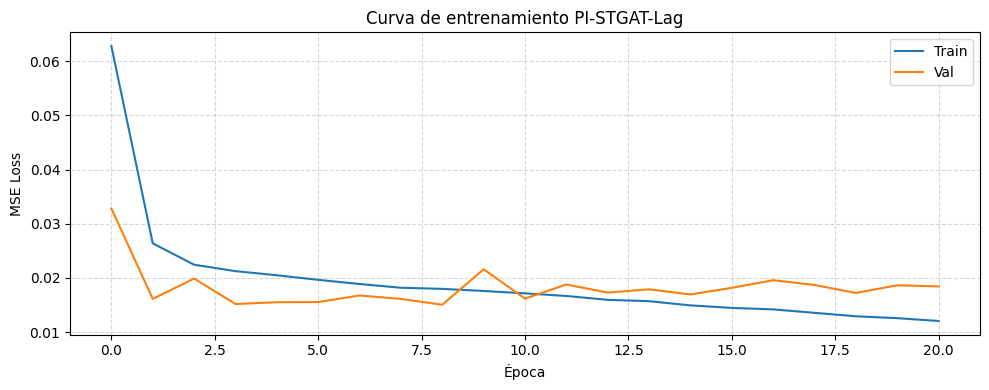

Mejor val loss: 0.01506  →  checkpoint: best_pi_stgat_lagged.pt


In [48]:
# =============================================================================
# Training
# =============================================================================
if CFG['eval_only']:
    print("eval_only=True → just validation")
else:
    optimizer  = torch.optim.Adam(model.parameters(),
                                  lr=CFG['lr'], weight_decay=1e-5)
    criterion  = nn.MSELoss()
    best_val   = float('inf')
    patience_c = 0
    ckpt_path  = 'best_pi_stgat_lagged.pt'
    train_losses, val_losses = [], []

    for epoch in range(1, CFG['epochs'] + 1):
        # --- train ---
        model.train()
        tr_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb, edge_index, x_static)  
            loss = criterion(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tr_loss += loss.item() * xb.size(0)
        tr_loss /= len(train_loader.dataset)

        # --- val ---
        model.eval()
        vl_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                pred = model(xb, edge_index, x_static)
                vl_loss += criterion(pred, yb).item() * xb.size(0)
        vl_loss /= len(val_loader.dataset)

        train_losses.append(tr_loss)
        val_losses.append(vl_loss)

        print(f"Epoch {epoch:03d}/{CFG['epochs']} | "
              f"Train: {tr_loss:.5f} | Val: {vl_loss:.5f}")

        if vl_loss < best_val:
            best_val   = vl_loss
            patience_c = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            patience_c += 1
            if patience_c >= CFG['patience']:
                print(f"Early stopping en época {epoch}.")
                break

    # Curva de pérdida
    plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label='Train')
    plt.plot(val_losses,   label='Val')
    plt.xlabel('Epochs'); plt.ylabel('MSE Loss')
    plt.title('Training curve PI-STGAT-Lag')
    plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout(); plt.show()
    print(f"Best val loss: {best_val:.5f}  →  checkpoint: {ckpt_path}")

## 12. Test set evaluation

In [49]:
# =============================================================================
# EVALUATION TEST SET
# =============================================================================
ckpt_path = 'best_pi_stgat_lagged.pt'
if not os.path.exists(ckpt_path):
    fallbacks = sorted(
        [f for f in os.listdir('.') if f.startswith('fallback_pi_stgat_lagged_')],
        key=lambda x: int(x.split('_')[-1].split('.')[0]), reverse=True
    )
    ckpt_path = fallbacks[0] if fallbacks else None

if ckpt_path:
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.M_lag = model.M_lag.to(device)   
    print(f"Checkpoint cargado: {ckpt_path}")
else:
    print("Not checkpoint found"")

model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        pred = model(xb, edge_index, x_static) 
        all_preds.append(pred.cpu().numpy())
        all_targets.append(yb.numpy())

all_preds   = np.concatenate(all_preds,   axis=0)
all_targets = np.concatenate(all_targets, axis=0)

preds_phys   = np.expm1(all_preds)
targets_phys = np.expm1(all_targets)
print(f"Test samples: {all_preds.shape[0]} | Nodos: {all_preds.shape[1]}")

Checkpoint cargado: best_pi_stgat_lagged.pt


C:\Users\usuario\AppData\Local\Temp\ipykernel_51988\1566160236.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(ckpt_path, map_location=

Test samples: 1426 | Nodos: 140


## 13. Water bodies metrics

In [50]:
# =============================================================================
# Metrics for water bodies
# =============================================================================
rows = []
for i, mass in enumerate(mass_list):
    t_true = targets_phys[:, i]
    t_pred = preds_phys[:, i]
    std_ok = np.std(t_true) > 0
    rows.append({
        'Water_Body_Code': mass,
        'NSE':  calculate_nse(t_true, t_pred) if std_ok else 0.0,
        'KGE':  calculate_kge(t_true, t_pred),
        'R2':   r2_score(t_true, t_pred)      if std_ok else 0.0,
        'RMSE_hm3':      np.sqrt(mean_squared_error(t_true, t_pred)),
        'MAE_hm3':       np.mean(np.abs(t_true - t_pred)),
        'PBIAS_percent': 100 * np.sum(t_pred - t_true) / (np.sum(t_true) + 1e-8),
    })

df_metrics = pd.DataFrame(rows)

os.makedirs('resultados_pp_runoff', exist_ok=True)
df_metrics.to_csv('resultados_pp_runoff/pi_stgat_lagged_metrics.csv',
                  index=False, sep=';')

print("\n--- Global summary (Test Set) ---")
print(f"Mean NSE:   {df_metrics['NSE'].mean():.4f}")
print(f"Median NSE: {df_metrics['NSE'].median():.4f}")
print(f"Mean KGE:   {df_metrics['KGE'].mean():.4f}")
print(f"Mean R2:    {df_metrics['R2'].mean():.4f}")
print(f"Mean RMSE:  {df_metrics['RMSE_hm3'].mean():.4f} HM3/día")
print(f"Mean PBIAS: {df_metrics['PBIAS_percent'].mean():.2f}%")
df_metrics.sort_values('NSE', ascending=False).head(10)


--- Resumen global (Test Set) ---
Mean NSE:   -3.7924
Median NSE: 0.3201
Mean KGE:   -0.1276
Mean R2:    -3.7924
Mean RMSE:  0.3114 HM3/día
Mean PBIAS: 47.93%


,Water_Body_Code,NSE,KGE,R2,RMSE_hm3,MAE_hm3,PBIAS_percent
0,18-01-02_,0.787564,0.767228,0.787564,0.106287,0.052552,-4.606964
7,18-04D_,0.764083,0.872060,0.764083,0.187270,0.091053,-3.593340
19,18-06B_,0.754524,0.761900,0.754524,0.319635,0.177695,18.993813
13,18-05_,0.751534,0.821911,0.751534,0.233848,0.115838,11.017262
2,18-01B_,0.733994,0.805976,0.733994,0.025014,0.013939,-4.930470
3,18-03_,0.733494,0.784859,0.733494,0.148841,0.071776,13.560956
4,18-04A_,0.732487,0.813670,0.732487,0.158254,0.078724,11.317651
66,18-21-01-06-01-01A_,0.728212,0.835539,0.728212,0.050599,0.035349,2.976639
1,18-01A_,0.717039,0.773452,0.717039,0.025338,0.012107,12.444794
18,18-06A_,0.714392,0.761384,0.714392,0.315075,0.154247,17.325525


## 14. Validation plots

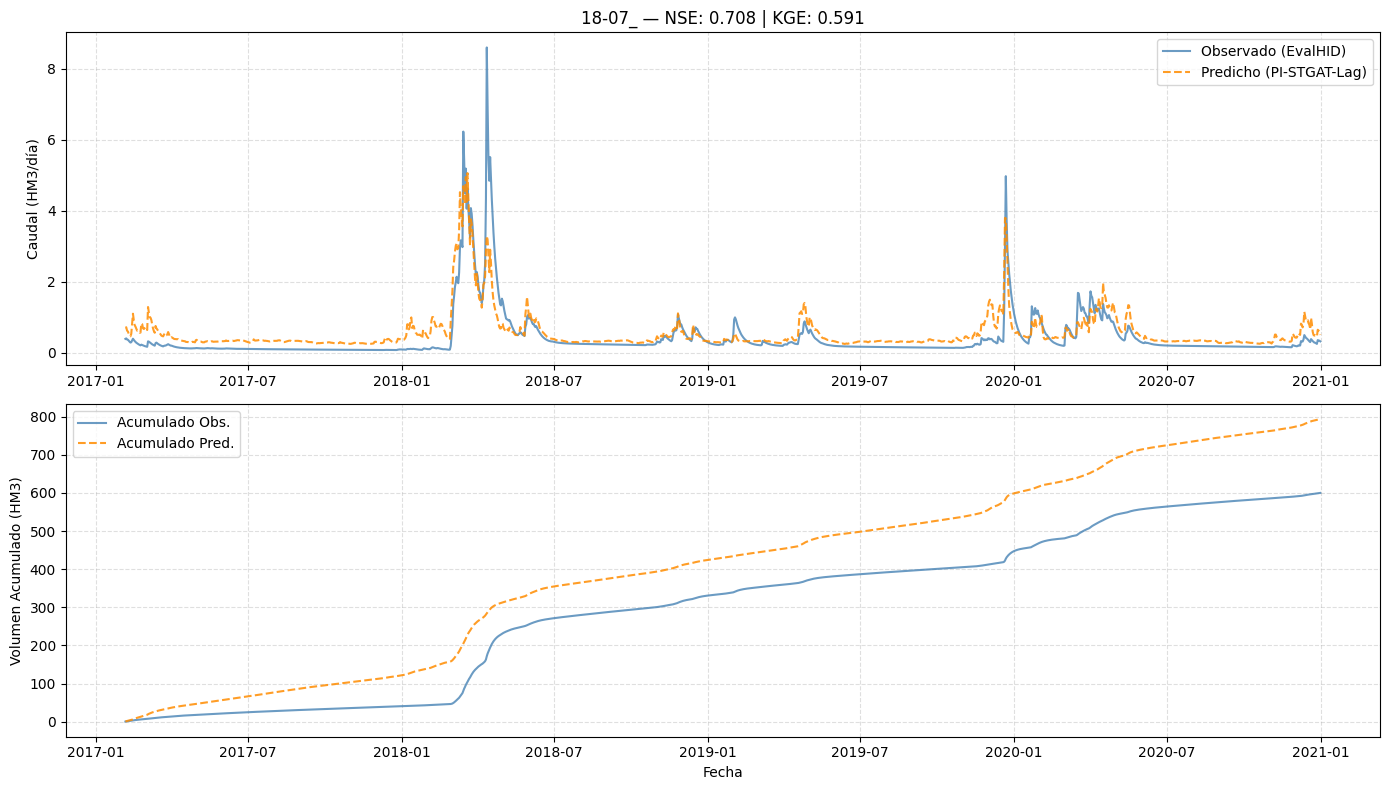

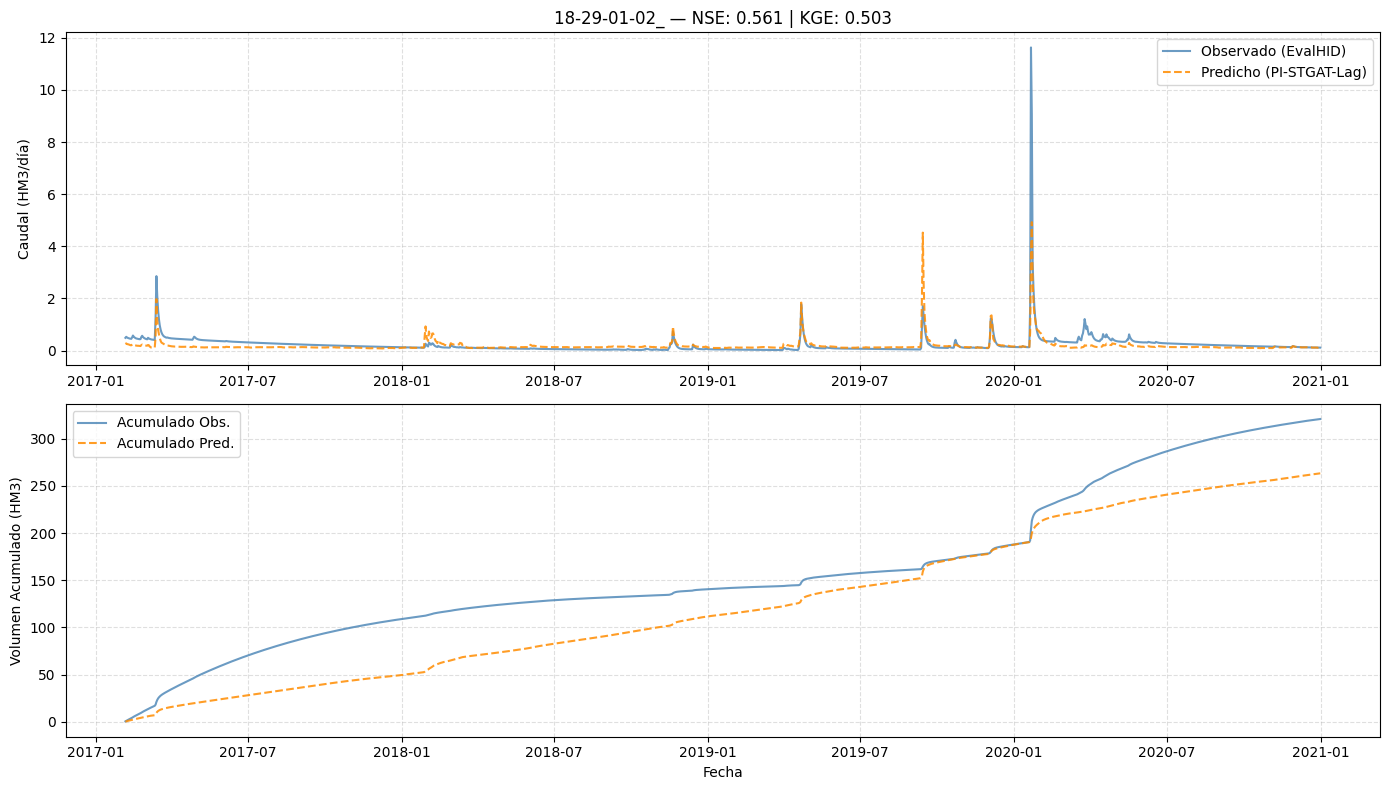

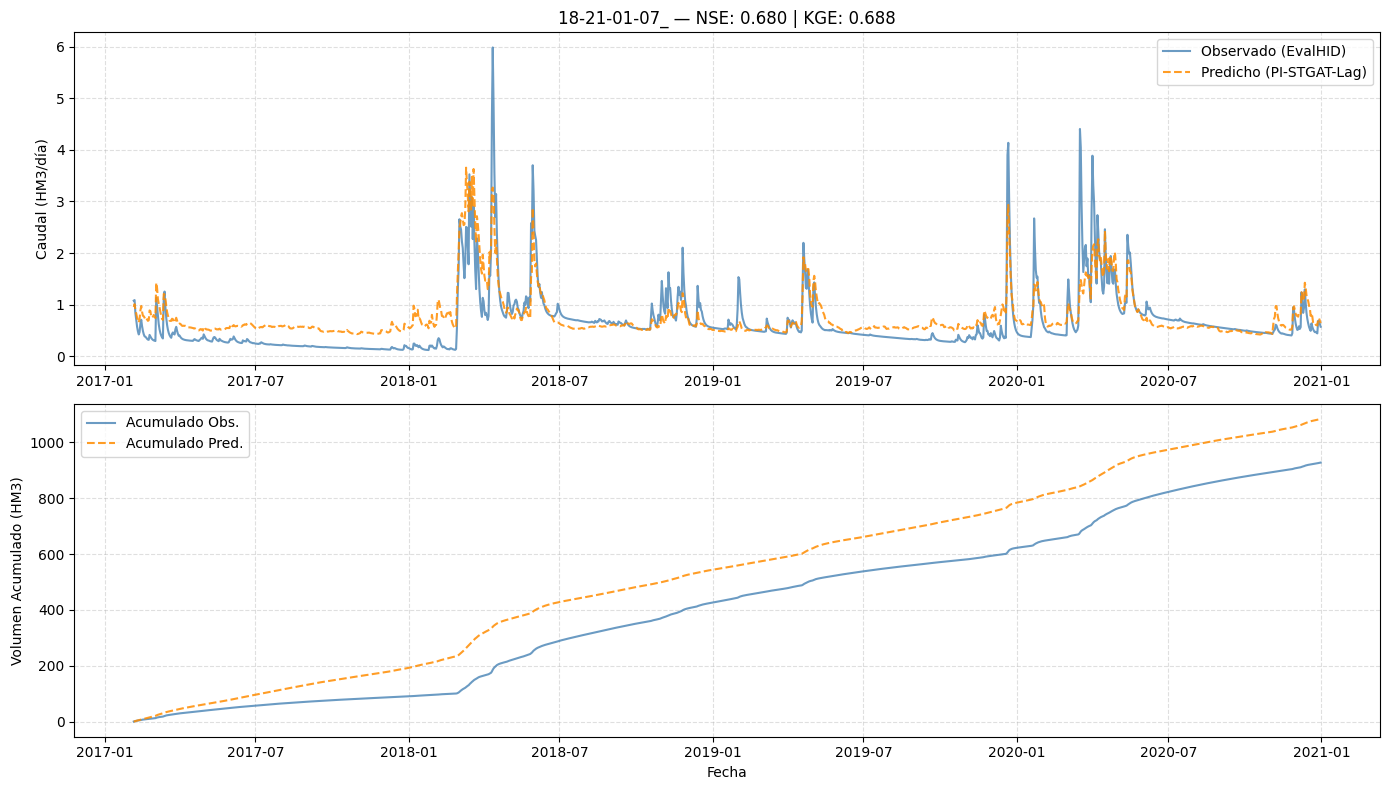

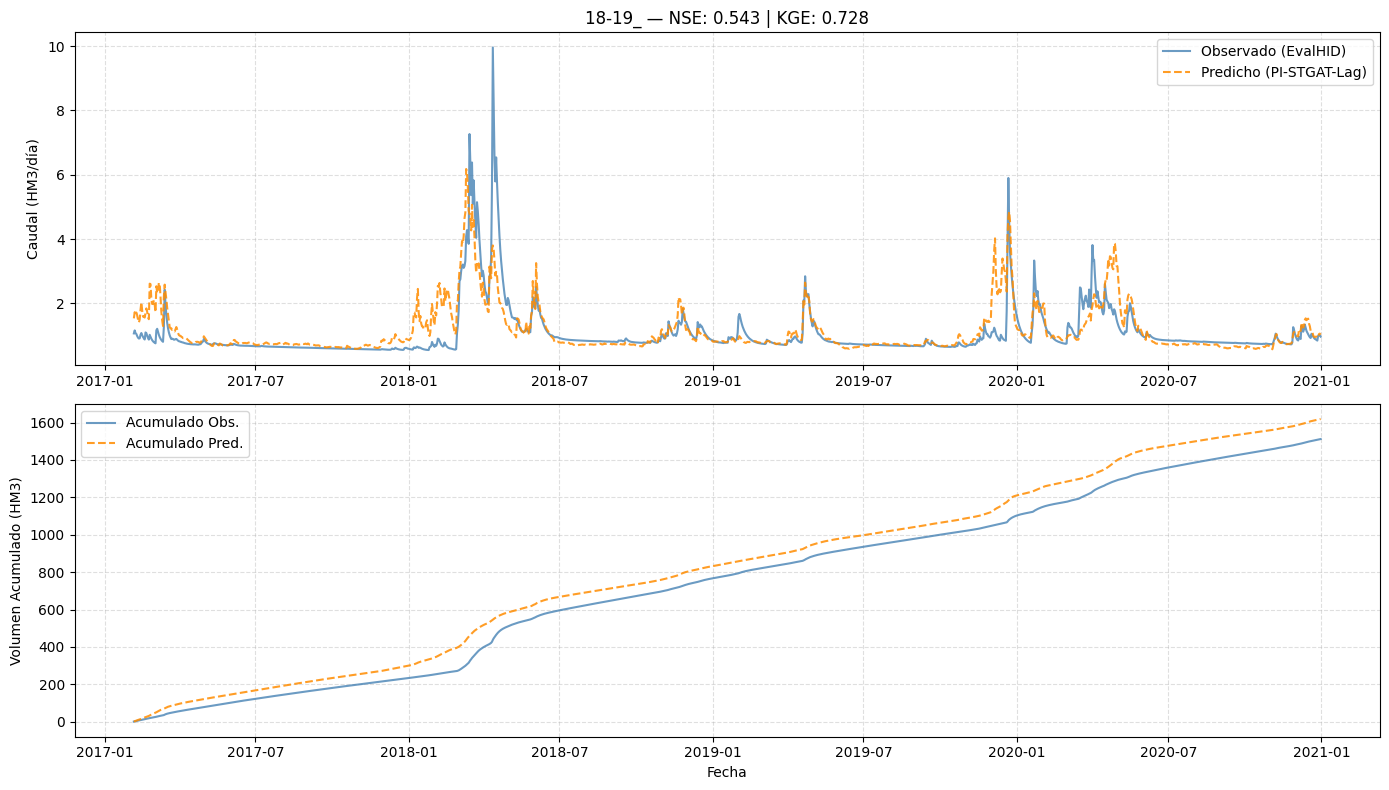

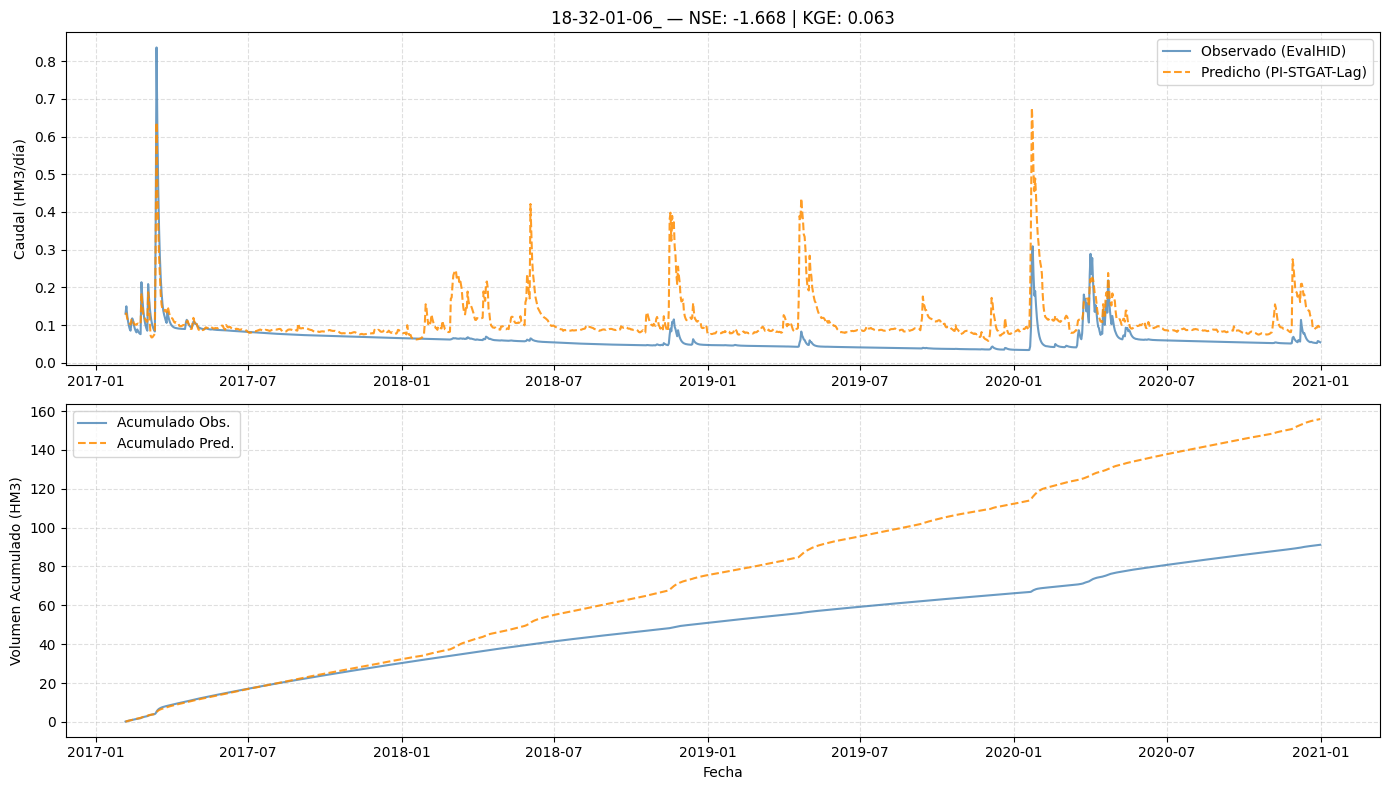

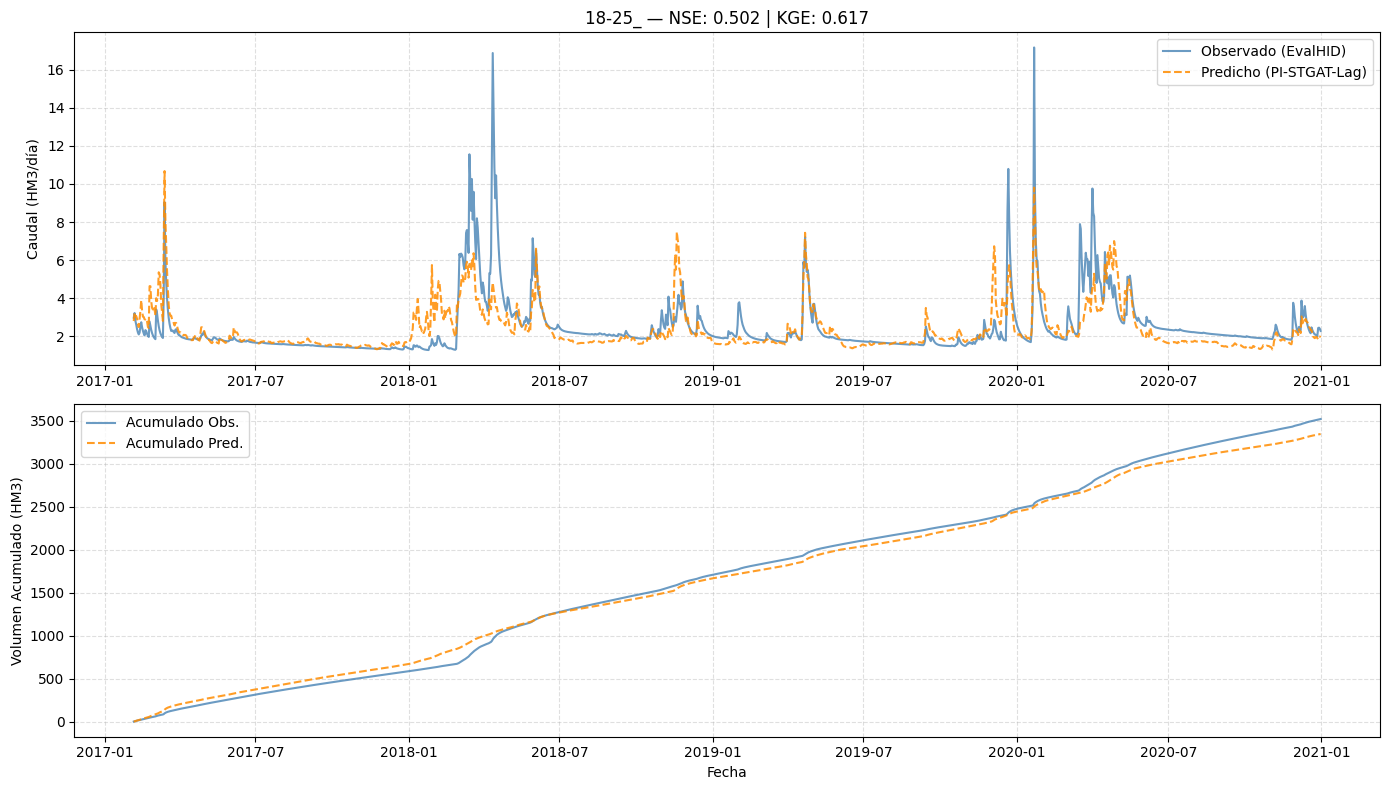

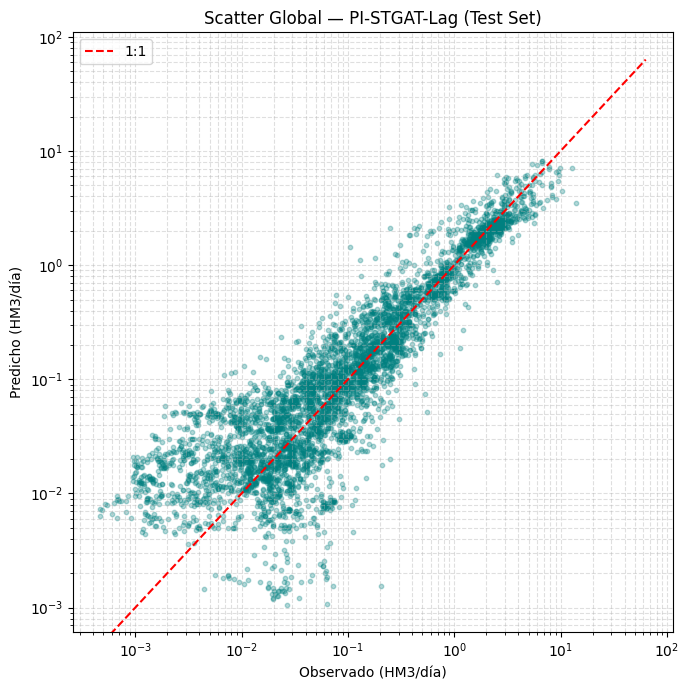

Gráficos guardados en plots/pi_stgat_lagged_validation


In [51]:
# =============================================================================
# Validation plots
# =============================================================================
out_dir = 'plots/pi_stgat_lagged_validation'
os.makedirs(out_dir, exist_ok=True)

test_dates = [pd.to_datetime(d) for d in metadata['dates'][val_end + W_total:]]

embalses = ['18-07_', '18-29-01-02_', '18-21-01-07_',
            '18-19_', '18-32-01-06_', '18-25_']

for mass_code in embalses:
    if mass_code not in mass_list:
        continue
    idx = mass_list.index(mass_code)
    row = df_metrics[df_metrics['Water_Body_Code'] == mass_code].iloc[0]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    # Hidrograma
    axes[0].plot(test_dates, targets_phys[:, idx],
                 label='Observed', color='steelblue', alpha=0.8)
    axes[0].plot(test_dates, preds_phys[:, idx],
                 label='Predict (PI-STGAT-Lag)', color='darkorange',
                 linestyle='--', alpha=0.85)
    axes[0].set_title(f"{mass_code} — NSE: {row['NSE']:.3f} | KGE: {row['KGE']:.3f}")
    axes[0].set_ylabel('HM3/day')
    axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.4)

    # Volumen acumulado
    axes[1].plot(test_dates, np.cumsum(targets_phys[:, idx]),
                 label='Accumulated observed', color='steelblue', alpha=0.8)
    axes[1].plot(test_dates, np.cumsum(preds_phys[:, idx]),
                 label='Accumulated predict', color='darkorange', linestyle='--', alpha=0.85)
    axes[1].set_ylabel('Accumulated volume (HM3)')
    axes[1].set_xlabel('Dates')
    axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(f'{out_dir}/{mass_code}.png', dpi=150)
    plt.show()

# Scatter global
fig, ax = plt.subplots(figsize=(7, 7))
flat_t = targets_phys.flatten()
flat_p = preds_phys.flatten()
if len(flat_t) > 5000:
    s = np.random.choice(len(flat_t), 5000, replace=False)
    ax.scatter(flat_t[s], flat_p[s], alpha=0.3, color='teal', s=10)
else:
    ax.scatter(flat_t, flat_p, alpha=0.3, color='teal', s=10)
mv = max(np.max(flat_t), np.max(flat_p))
ax.plot([0, mv], [0, mv], 'r--', label='1:1')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Observed (HM3/day)'); ax.set_ylabel('Predict (HM3/day)')
ax.set_title('Scatter Global — PI-STGAT-Lag (Test Set)')
ax.legend(); ax.grid(True, which='both', linestyle='--', alpha=0.4)
plt.tight_layout(); plt.savefig(f'{out_dir}/scatter.png', dpi=150); plt.show()
print("Plots saved in", out_dir)

In [72]:
# =============================================================================
# SELECCIONAR Y CARGAR EL MEJOR MODELO DEL RANDOM SEARCH
# =============================================================================
import shutil

# Mejor trial según NSE en val
best_row = df_results.iloc[0]
print(f"Mejor trial: #{int(best_row['trial_id'])}")
print(f"  NSE (val) : {best_row['mean_nse']:.4f}")
print(f"  hidden_dim: {int(best_row['hidden_dim'])}  num_heads: {int(best_row['num_heads'])}")
print(f"  dropout   : {best_row['dropout']}  num_layers: {int(best_row['num_layers'])}")

# Instanciar modelo con los hiperparámetros del mejor trial
best_model = PISTGATLagged(
    num_climate_features = len(climate_indices),
    static_dim           = static_features_np.shape[1],
    hidden_dim           = int(best_row['hidden_dim']),
    window_gru           = FIXED['window_gru'],
    max_lag              = FIXED['max_lag'],
    num_heads            = int(best_row['num_heads']),
    dropout              = float(best_row['dropout']),
    num_layers           = int(best_row['num_layers']),
).to(device)

# Cargar pesos del checkpoint del mejor trial
best_ckpt_path = f"trial_{int(best_row['trial_id']):02d}_best.pt"
best_model.set_mlag(M_lag_np)
best_model.M_lag = best_model.M_lag.to(device)
best_model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
best_model.eval()

# Copiar como checkpoint canónico
shutil.copy(best_ckpt_path, 'best_pi_stgat_lagged_tunned.pt')
print(f"\nCheckpoint copiado a: best_pi_stgat_lagged.pt")

Mejor trial: #10
  NSE (val) : -3.2833
  hidden_dim: 128  num_heads: 2
  dropout   : 0.1  num_layers: 1

Checkpoint copiado a: best_pi_stgat_lagged.pt


C:\Users\usuario\AppData\Local\Temp\ipykernel_51988\2831312426.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_model.load_state_dict(torch.load(best_ckpt_path, map

=== Test Set — Mejor Trial ===
Mean NSE   : -2.3704
Median NSE : 0.3666
Mean KGE   : 0.0178
Mean RMSE  : 0.3040 HM3/día


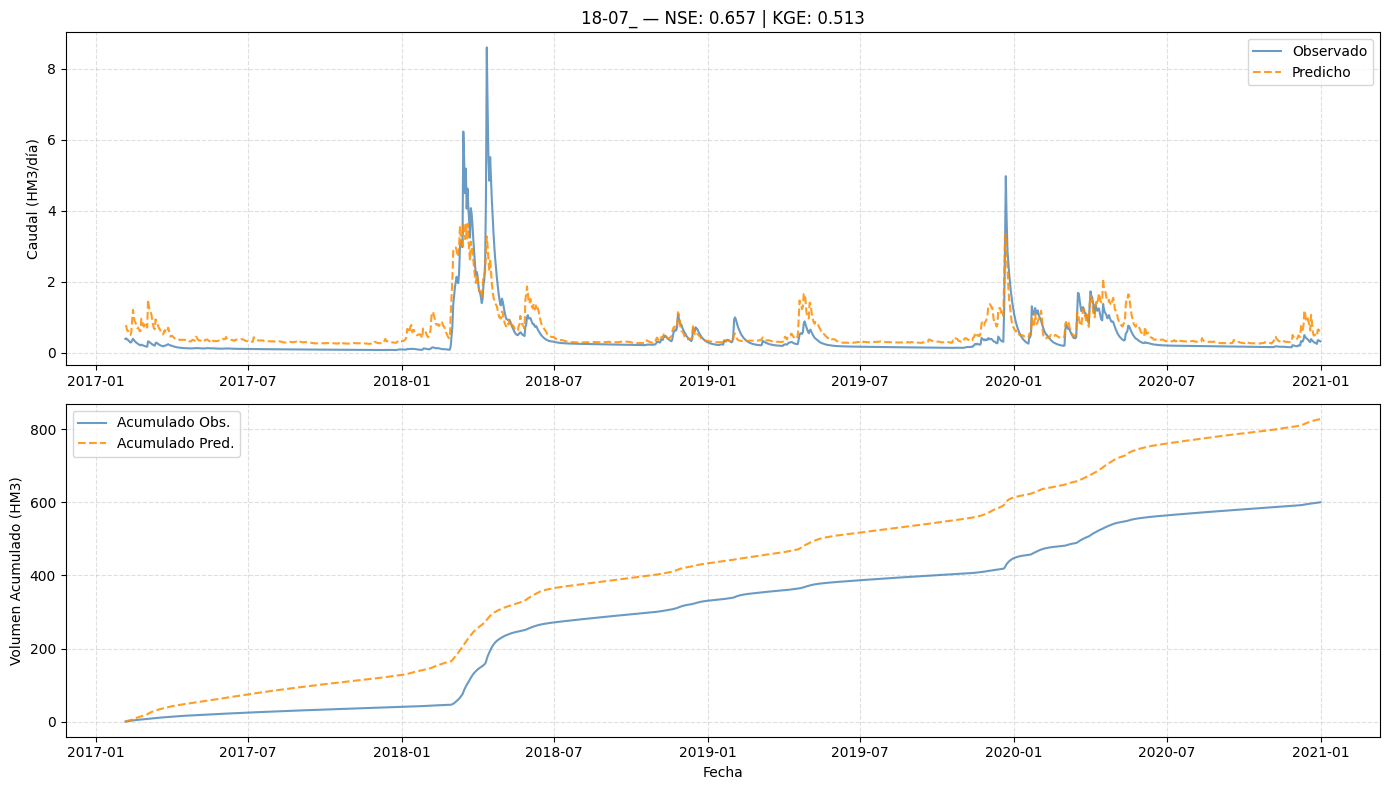

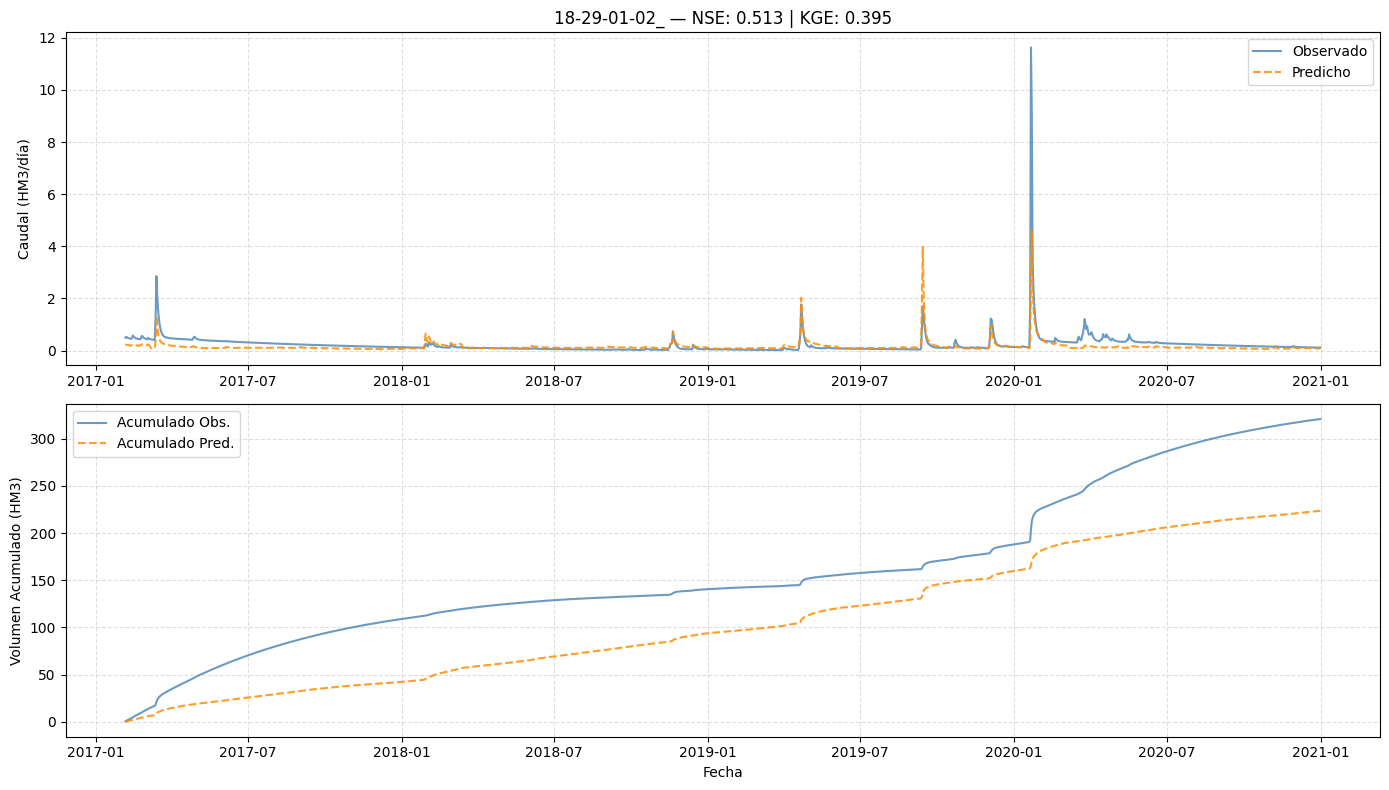

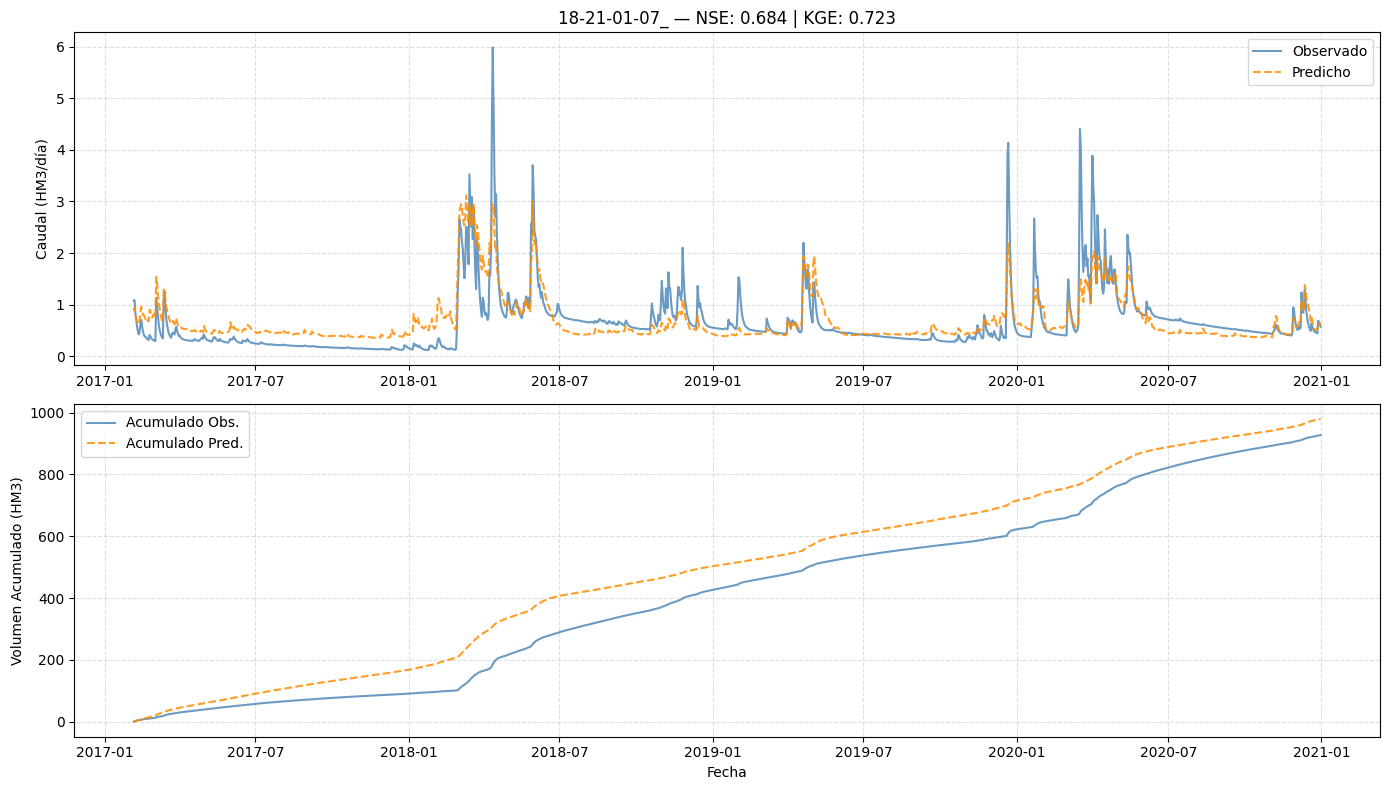

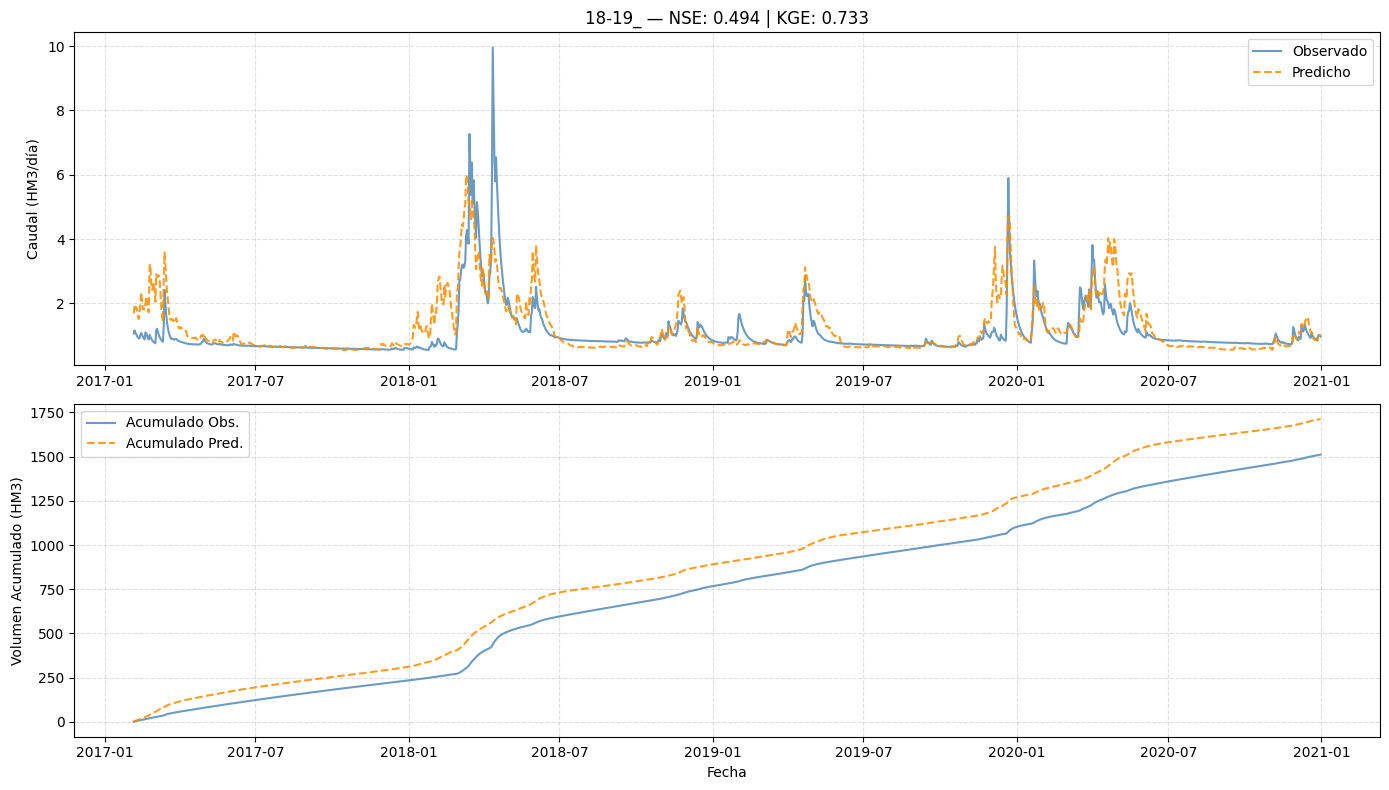

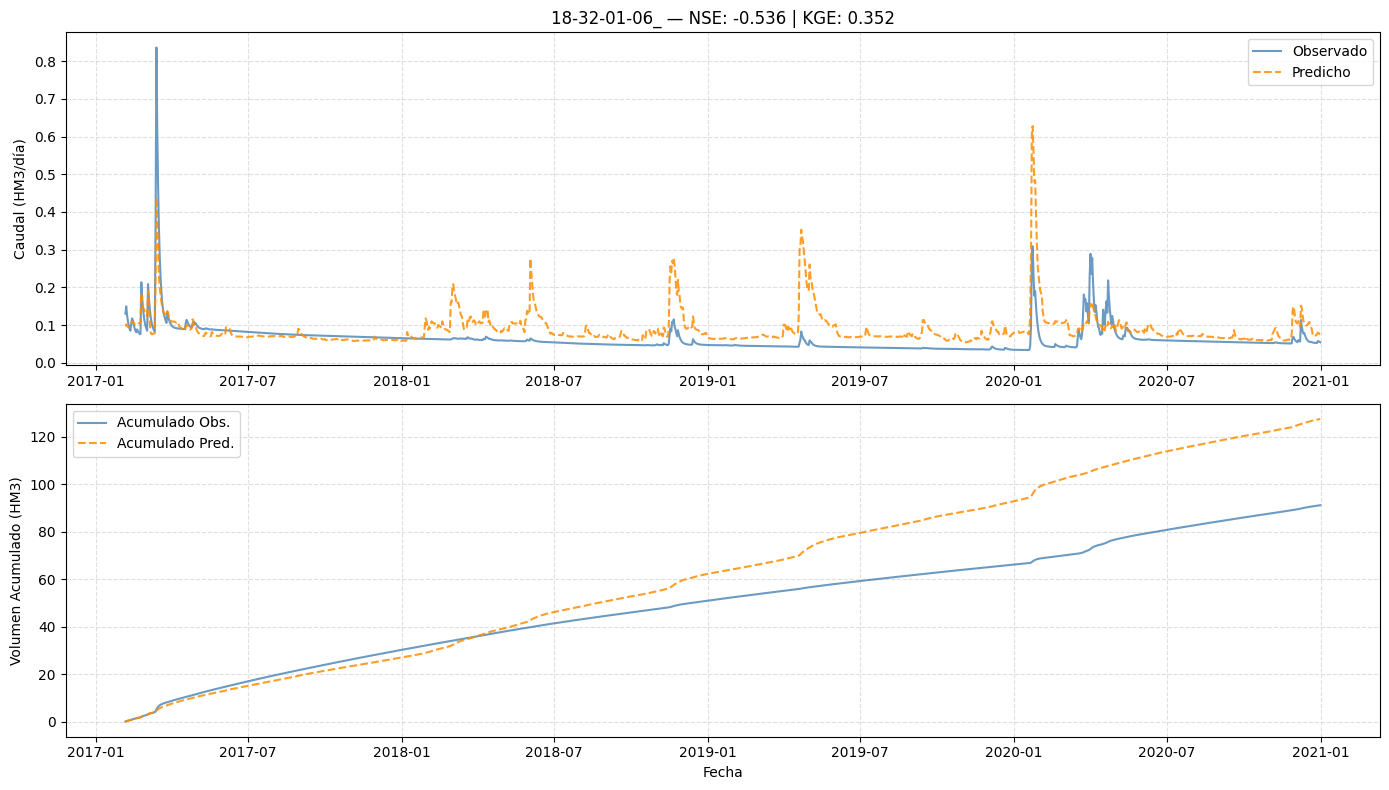

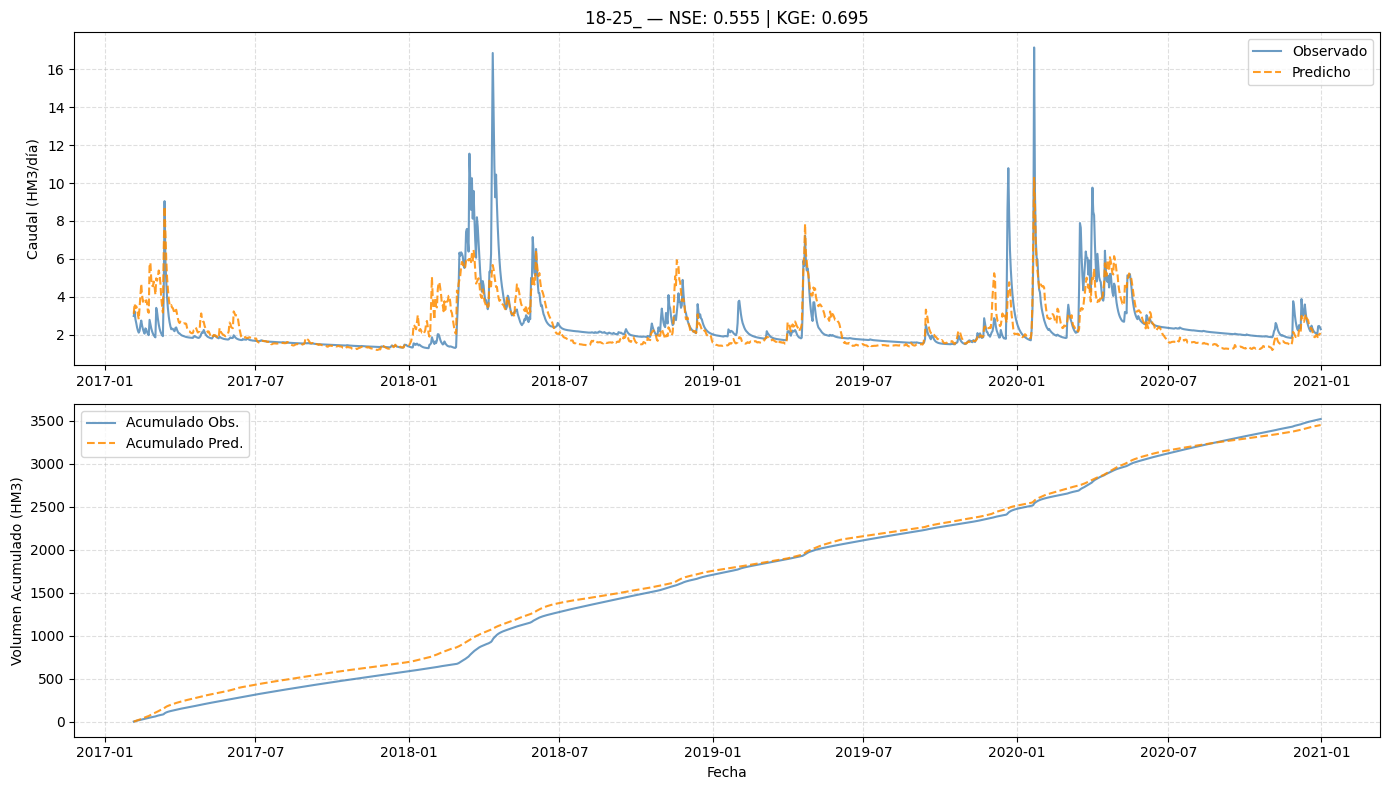

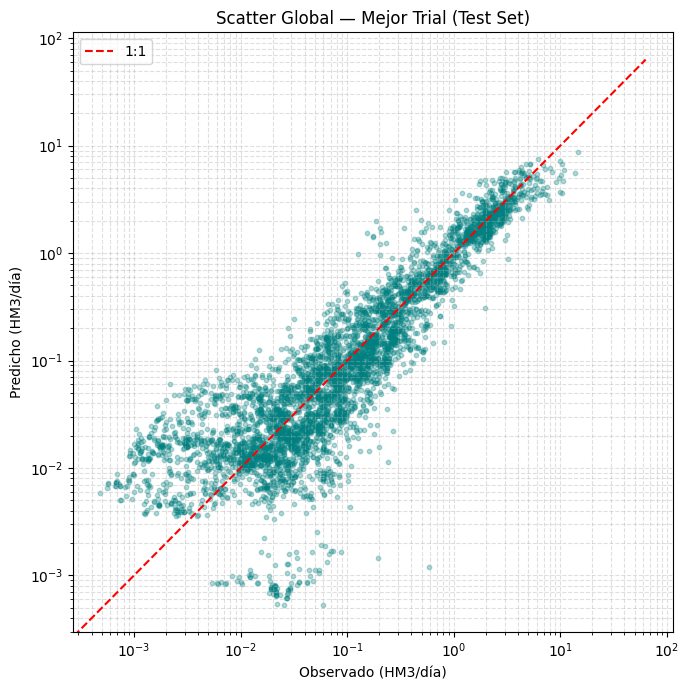

Gráficos guardados en: plots/best_trial_validation_tunning


In [73]:
# =============================================================================
# EVALUACIÓN DEL MEJOR MODELO SOBRE TEST SET
# =============================================================================
# --- Inferencia ---
all_preds, all_targets = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        pred = best_model(xb, edge_index, x_static)
        all_preds.append(pred.cpu().numpy())
        all_targets.append(yb.numpy())

preds_phys   = np.expm1(np.concatenate(all_preds,   axis=0))
targets_phys = np.expm1(np.concatenate(all_targets, axis=0))

# --- Métricas ---
rows = []
for i, mass in enumerate(mass_list):
    t, p = targets_phys[:, i], preds_phys[:, i]
    std_ok = np.std(t) > 0
    rows.append({
        'Water_Body_Code': mass,
        'NSE' : calculate_nse(t, p) if std_ok else 0.0,
        'KGE' : calculate_kge(t, p),
        'R2'  : r2_score(t, p)      if std_ok else 0.0,
        'RMSE_hm3'      : np.sqrt(mean_squared_error(t, p)),
        'MAE_hm3'       : np.mean(np.abs(t - p)),
        'PBIAS_percent' : 100 * np.sum(p - t) / (np.sum(t) + 1e-8),
    })

df_metrics = pd.DataFrame(rows)
df_metrics.to_csv('resultados_pp_runoff/best_trial_metrics_test_tuning.csv', index=False, sep=';')

print("=== Test Set — Mejor Trial ===")
print(f"Mean NSE   : {df_metrics['NSE'].mean():.4f}")
print(f"Median NSE : {df_metrics['NSE'].median():.4f}")
print(f"Mean KGE   : {df_metrics['KGE'].mean():.4f}")
print(f"Mean RMSE  : {df_metrics['RMSE_hm3'].mean():.4f} HM3/día")

# --- Gráficos ---
out_dir    = 'plots/best_trial_validation_tunning'
os.makedirs(out_dir, exist_ok=True)
test_dates = [pd.to_datetime(d) for d in metadata['dates'][val_end + W_total:]]
embalses   = ['18-07_', '18-29-01-02_', '18-21-01-07_',
              '18-19_', '18-32-01-06_', '18-25_']

for mass_code in embalses:
    if mass_code not in mass_list:
        continue
    idx = mass_list.index(mass_code)
    row = df_metrics[df_metrics['Water_Body_Code'] == mass_code].iloc[0]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    axes[0].plot(test_dates, targets_phys[:, idx],
                 label='Observado', color='steelblue', alpha=0.8)
    axes[0].plot(test_dates, preds_phys[:, idx],
                 label='Predicho', color='darkorange', linestyle='--', alpha=0.85)
    axes[0].set_title(f"{mass_code} — NSE: {row['NSE']:.3f} | KGE: {row['KGE']:.3f}")
    axes[0].set_ylabel('Caudal (HM3/día)')
    axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.4)

    axes[1].plot(test_dates, np.cumsum(targets_phys[:, idx]),
                 label='Acumulado Obs.', color='steelblue', alpha=0.8)
    axes[1].plot(test_dates, np.cumsum(preds_phys[:, idx]),
                 label='Acumulado Pred.', color='darkorange', linestyle='--', alpha=0.85)
    axes[1].set_ylabel('Volumen Acumulado (HM3)'); axes[1].set_xlabel('Fecha')
    axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(f'{out_dir}/{mass_code}.png', dpi=150)
    plt.show()

# Scatter global
fig, ax = plt.subplots(figsize=(7, 7))
ft, fp  = targets_phys.flatten(), preds_phys.flatten()
s       = np.random.choice(len(ft), min(5000, len(ft)), replace=False)
ax.scatter(ft[s], fp[s], alpha=0.3, color='teal', s=10)
mv = max(ft.max(), fp.max())
ax.plot([0, mv], [0, mv], 'r--', label='1:1')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Observado (HM3/día)'); ax.set_ylabel('Predicho (HM3/día)')
ax.set_title('Scatter Global — Mejor Trial (Test Set)')
ax.legend(); ax.grid(True, which='both', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(f'{out_dir}/scatter.png', dpi=150)
plt.show()

print(f"Gráficos guardados en: {out_dir}")